# 01 - DQN on LunarLander-v3

**Deep Q-Network (DQN)** learns an approximation of the optimal action-value
function $Q^\*(s,a)$ with a neural network. Actions are chosen $\epsilon$-greedy
and transitions are stored in a replay buffer. The bootstrap target uses a
**target network** $\theta^-$ updated less frequently than the online network:

$$y_t = r_t + \gamma\, \max_{a'} Q_{\theta^-}(s_{t+1}, a').$$

**What this notebook does**
1. Define the Q-network and a replay buffer.
2. Train until solved (mean return over the last 100 episodes $\geq 200$), capped at 800 episodes.
3. Log per-episode return, episode length, epsilon, and **mean predicted Q** (used later to study overestimation vs DDQN).
4. Save the trained model, logs, and plots.

In [1]:
import os, csv, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import gymnasium as gym
import matplotlib.pyplot as plt

DEVICE = torch.device('cpu')  # small MLPs: CPU beats MPS here (benchmarked)
ENV_ID = 'LunarLander-v3'      # discrete actions, shared across DQN/DDQN/PPO
SEED = 0

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def moving_average(x, w=100):
    x = np.asarray(x, dtype=np.float32)
    if len(x) < 1:
        return x
    return np.convolve(x, np.ones(w)/w, mode='valid')

print('Algorithm: DQN')
print('Torch', torch.__version__, '| device', DEVICE, '| env', ENV_ID)

Algorithm: DQN
Torch 2.12.0 | device cpu | env LunarLander-v3


In [2]:
# --- Hyperparameters ---
GAMMA          = 0.99
LR             = 5e-4
BATCH_SIZE     = 64
BUFFER_SIZE    = 100_000
EPS_START      = 1.0
EPS_END        = 0.02
EPS_DECAY      = 0.99      # per episode
LEARNING_STARTS= 1_000     # env steps before first update
TARGET_UPDATE  = 1_000     # hard-copy target net every N env steps
MAX_EPISODES   = 800
MAX_STEPS      = 1_000     # env truncates at 1000 anyway
SOLVED_SCORE   = 200.0     # mean over last 100 episodes

MODEL_DIR = '../models/dqn'; LOG_DIR = '../logs/dqn'; FIG_DIR = '../figures/dqn'
for d in (MODEL_DIR, LOG_DIR, FIG_DIR): os.makedirs(d, exist_ok=True)

In [3]:
class QNetwork(nn.Module):
    """128-64 MLP. Identical architecture to the DDQN notebook for a fair comparison."""
    def __init__(self, obs_dim, n_actions):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, n_actions),
        )
    def forward(self, x):
        return self.net(x)

class ReplayBuffer:
    def __init__(self, capacity):
        self.capacity = int(capacity); self.buffer = []; self.pos = 0
    def push(self, s, a, r, s2, d):
        if len(self.buffer) < self.capacity: self.buffer.append(None)
        self.buffer[self.pos] = (s, a, r, s2, d)
        self.pos = (self.pos + 1) % self.capacity
    def sample(self, n):
        batch = random.sample(self.buffer, n)
        s, a, r, s2, d = zip(*batch)
        return (np.array(s, np.float32), np.array(a, np.int64),
                np.array(r, np.float32), np.array(s2, np.float32), np.array(d, np.float32))
    def __len__(self):
        return len(self.buffer)

In [4]:
def train_dqn():
    set_seed(SEED)
    env = gym.make(ENV_ID)
    env.reset(seed=SEED)
    obs_dim = env.observation_space.shape[0]; n_actions = env.action_space.n

    q = QNetwork(obs_dim, n_actions).to(DEVICE)
    q_target = QNetwork(obs_dim, n_actions).to(DEVICE)
    q_target.load_state_dict(q.state_dict())
    opt = optim.Adam(q.parameters(), lr=LR)
    buf = ReplayBuffer(BUFFER_SIZE)

    csv_path = os.path.join(LOG_DIR, 'train_log.csv')
    with open(csv_path, 'w', newline='') as fh:
        csv.writer(fh).writerow(['episode','reward','length','epsilon','mean_q','timesteps'])

    eps = EPS_START; rewards = []; global_step = 0
    solved_ep = None; t0 = time.time()
    for ep in range(1, MAX_EPISODES + 1):
        obs, _ = env.reset()
        ep_r = 0.0; ep_q = []
        for t in range(MAX_STEPS):
            global_step += 1
            if random.random() < eps:
                action = env.action_space.sample()
            else:
                with torch.no_grad():
                    ov = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                    action = int(q(ov).argmax(dim=-1).item())
            nobs, r, term, trunc, _ = env.step(action)
            buf.push(obs, action, r, nobs, float(term))  # bootstrap through truncation
            obs = nobs; ep_r += r

            if len(buf) >= max(BATCH_SIZE, LEARNING_STARTS):
                s, a, rw, s2, d = buf.sample(BATCH_SIZE)
                s = torch.as_tensor(s, device=DEVICE); s2 = torch.as_tensor(s2, device=DEVICE)
                a = torch.as_tensor(a, device=DEVICE); rw = torch.as_tensor(rw, device=DEVICE)
                d = torch.as_tensor(d, device=DEVICE)
                qv = q(s).gather(1, a.unsqueeze(-1)).squeeze(-1)
                with torch.no_grad():
                    max_next = q_target(s2).max(1)[0]                  # DQN: max from target net
                    target = rw + GAMMA * max_next * (1.0 - d)
                loss = nn.functional.mse_loss(qv, target)
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(q.parameters(), 10.0)
                opt.step()
                ep_q.append(qv.mean().item())
                if global_step % TARGET_UPDATE == 0:
                    q_target.load_state_dict(q.state_dict())

            if term or trunc:
                break

        eps = max(EPS_END, eps * EPS_DECAY)
        rewards.append(ep_r)
        avg100 = np.mean(rewards[-100:])
        mean_q = float(np.mean(ep_q)) if ep_q else float('nan')
        with open(csv_path, 'a', newline='') as fh:
            csv.writer(fh).writerow([ep, ep_r, t+1, eps, mean_q, global_step])
        if ep % 20 == 0:
            print(f'Ep {ep:4d} | R {ep_r:8.2f} | avg100 {avg100:8.2f} | eps {eps:.3f} | Q {mean_q:7.2f} | steps {global_step}')
        if avg100 >= SOLVED_SCORE and len(rewards) >= 100:
            solved_ep = ep
            print(f'\nSOLVED at episode {ep}: avg100 = {avg100:.2f}')
            break

    torch.save(q.state_dict(), os.path.join(MODEL_DIR, 'dqn_final.pt'))
    np.save(os.path.join(LOG_DIR, 'rewards.npy'), np.array(rewards))
    print(f'Done in {time.time()-t0:.1f}s | episodes {len(rewards)} | solved_ep {solved_ep}')
    env.close()
    return rewards, solved_ep

rewards, solved_ep = train_dqn()

Ep   20 | R   -90.50 | avg100  -188.95 | eps 0.818 | Q   -1.16 | steps 2027


Ep   40 | R   -93.50 | avg100  -158.56 | eps 0.669 | Q    1.42 | steps 4422


Ep   60 | R   -49.89 | avg100  -127.96 | eps 0.547 | Q    3.76 | steps 8330


Ep   80 | R   -87.51 | avg100  -108.06 | eps 0.448 | Q    6.34 | steps 13133


Ep  100 | R    34.62 | avg100   -96.16 | eps 0.366 | Q   12.78 | steps 26706


...

Ep  200 | R   209.83 | avg100    87.31 | eps 0.134 | Q   29.60 | steps 102341


Ep  220 | R   250.08 | avg100   133.92 | eps 0.110 | Q   30.50 | steps 116102


Ep  240 | R   306.71 | avg100   160.76 | eps 0.090 | Q   29.40 | steps 130554


Ep  260 | R   253.88 | avg100   190.48 | eps 0.073 | Q   30.37 | steps 140643



SOLVED at episode 270: avg100 = 200.35
Done in 75.2s | episodes 270 | solved_ep 270


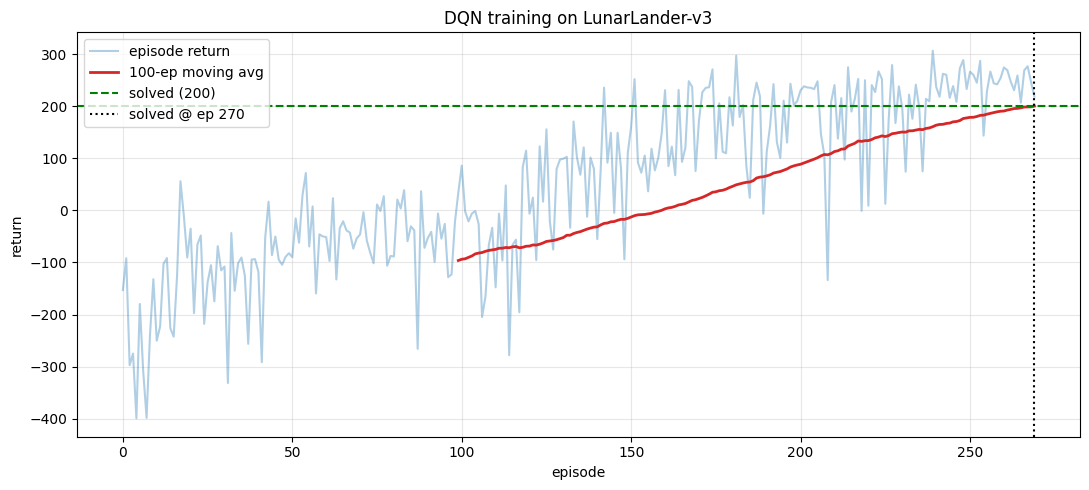

final 100-ep avg: 200.35486923085514


In [5]:
# --- Training curve + 100-episode moving average ---
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(rewards, alpha=0.35, label='episode return')
ma = moving_average(rewards, 100)
ax.plot(range(99, 99+len(ma)), ma, color='C3', lw=2, label='100-ep moving avg')
ax.axhline(200, color='green', ls='--', lw=1.5, label='solved (200)')
if solved_ep: ax.axvline(solved_ep-1, color='k', ls=':', label=f'solved @ ep {solved_ep}')
ax.set_xlabel('episode'); ax.set_ylabel('return'); ax.set_title('DQN training on LunarLander-v3')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'dqn_training.png'), dpi=110); plt.show()
print('final 100-ep avg:', float(np.mean(rewards[-100:])))

**Result.** The saved model (`../models/dqn/dqn_final.pt`) and the per-episode log
(`../logs/dqn/train_log.csv`, including `mean_q` for the overestimation study) feed the
execution and comparison notebooks. DQN is expected to solve but with a noisier curve than
DDQN/PPO because of value overestimation and off-policy bootstrapping.